In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx
import numpy as np

In [3]:
buildings = gpd.read_parquet("../../data/raw/osm_buildings_92037.parquet")
boundary = gpd.read_parquet("../../data/raw/zcta_92037.parquet")
basemap = cx.providers.Esri.WorldGrayCanvas

print(len(buildings), "buildings |", buildings.crs.to_string())
buildings.head()

14316 buildings | EPSG:32611


,element,id,building,name,addr:housenumber,addr:street,building:levels,geometry
0,relation,2446441,yes,La Jolla Beach and Tennis Club,2000,Spindrift Drive,NaN,"POLYGON ((475642.104 3634983.161, 475637.454 3..."
1,relation,2446523,yes,La Jolla Shores Hotel,8110,Camino del Oro,NaN,"POLYGON ((475795.976 3635198.159, 475794.461 3..."
2,relation,6089138,yes,Sheraton La Jolla Hotel,NaN,NaN,NaN,"MULTIPOLYGON (((478371.563 3636899.275, 478316..."
3,relation,6729677,yes,Campus Point Parking Structure,NaN,NaN,NaN,"MULTIPOLYGON (((478877.694 3638009.128, 478899..."
4,relation,7989489,house,NaN,NaN,NaN,NaN,"POLYGON ((476538.204 3638307.899, 476538.224 3..."


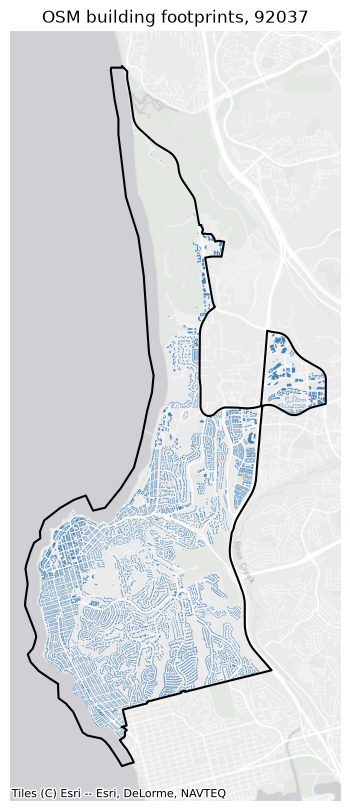

In [4]:
fig, ax = plt.subplots(figsize=(10, 10))
buildings.plot(ax=ax, color="steelblue")
boundary.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1.5)
cx.add_basemap(ax, crs=buildings.crs, source=basemap)
ax.set_title("OSM building footprints, 92037")
ax.set_axis_off()

In [5]:
import duckdb

con = duckdb.connect()
con.execute("INSTALL spatial; LOAD spatial;")

query = """
    SELECT COUNT(*) AS building_count
    FROM '../../data/raw/osm_buildings_92037.parquet'
"""

building_count = con.execute(query).fetchone()[0]
print(f"92037 Building count: {building_count:,} buildings")

92037 Building count: 14,316 buildings


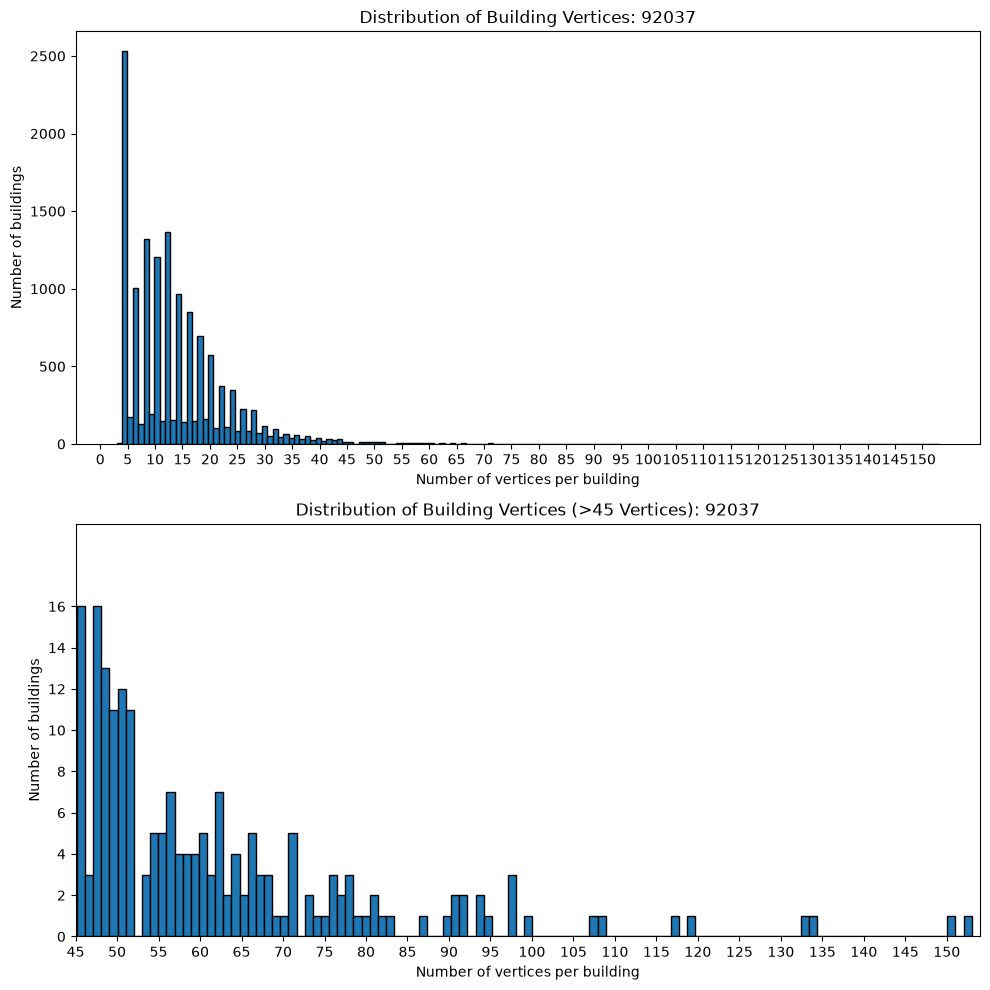

In [6]:
def vertex_count(geometry):
    if geometry.geom_type == "Polygon":
        return len(geometry.exterior.coords) - 1
    return sum(len(polygon.exterior.coords) - 1 for polygon in geometry.geoms)

buildings["vertex_count"] = buildings.geometry.apply(vertex_count)
max_vertex_count = buildings["vertex_count"].max()

fig, (ax, ax_lim) = plt.subplots(2, 1, figsize=(10, 10))
ax.hist(buildings["vertex_count"], bins=max_vertex_count, edgecolor="black")
ax.set_xlabel("Number of vertices per building")
ax.set_ylabel("Number of buildings")
ax.set_title("Distribution of Building Vertices: 92037")
ax.set_xticks(np.arange(0, max_vertex_count + 1, 5))
ax_lim.hist(buildings["vertex_count"], bins=max_vertex_count, edgecolor="black")
ax_lim.set_xlabel("Number of vertices per building")
ax_lim.set_ylabel("Number of buildings")
ax_lim.set_title("Distribution of Building Vertices (>45 Vertices): 92037")
ax_lim.set_xlim(45, max_vertex_count+1)
ax_lim.set_ylim(0, 20)
ax_lim.set_xticks(np.arange(45, max_vertex_count + 1, 5))
ax_lim.set_yticks(np.arange(0, 17, 2))
plt.tight_layout()
plt.show()

As expected, the number of buildings decreases as the number of vertices increases. The most common number of vertices is 4, which would be a simple rectangle. The majority of buildings have an even number of vertices, which is expected since most buildings have right angle corners and shapes consisting of rectangles. After 45 vertices, the distribution is much more irregular, which is because of the much smaller number of buildings with number of vertices in these ranges. Something interesting is that after 4, the most common number of vertices is 10 (instead of 6 or 8).

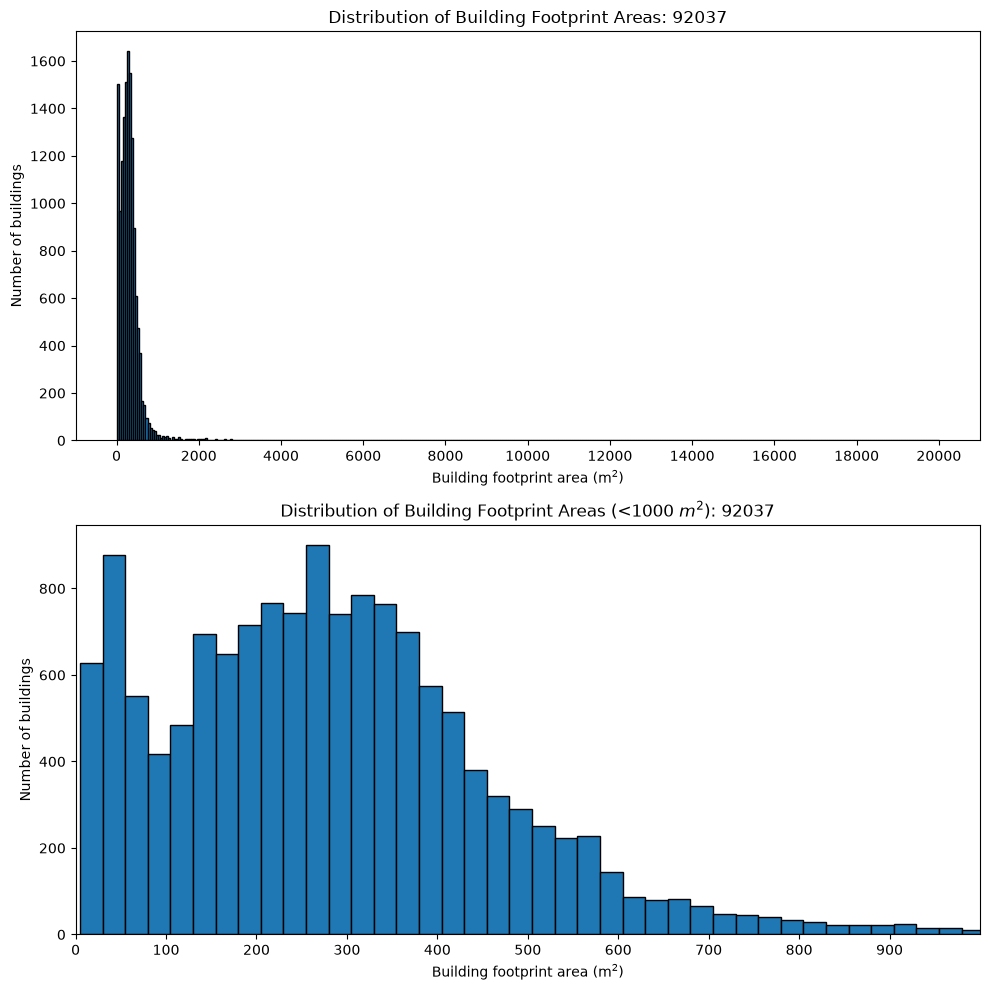

In [9]:
query = """
    SELECT
        ST_Area(geometry) AS area_m2
    FROM '../../data/raw/osm_buildings_92037.parquet'
    WHERE geometry IS NOT NULL
"""
area_df = con.execute(query).df()

fig, (ax, ax_lim) = plt.subplots(2, 1, figsize=(10, 10))
ax.hist(
    area_df["area_m2"],
    bins= 400,
    edgecolor="black"
)
ax.set_xlabel(f"Building footprint area (m$^2$)")
ax.set_ylabel("Number of buildings")
ax.set_title("Distribution of Building Footprint Areas: 92037")
ax.set_xticks(np.arange(0, 21_000, 2000))
ax_lim.hist(
    area_df["area_m2"],
    bins=800,
    edgecolor="black"
)
ax_lim.set_xlabel(f"Building footprint area (m$^2$)")
ax_lim.set_ylabel("Number of buildings")
ax_lim.set_title(f"Distribution of Building Footprint Areas (<1000 $m^2$): 92037")
ax_lim.set_xlim(0, 1000)
ax_lim.set_xticks(np.arange(0, 1000, 100))
plt.tight_layout()
plt.show()


Most buildings have an area of under $1000m^2$, with the overall histogram not having much data beyond that point. There seems to be a spike at around $25-50m^2$, with the overall distribution being right-skewed.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

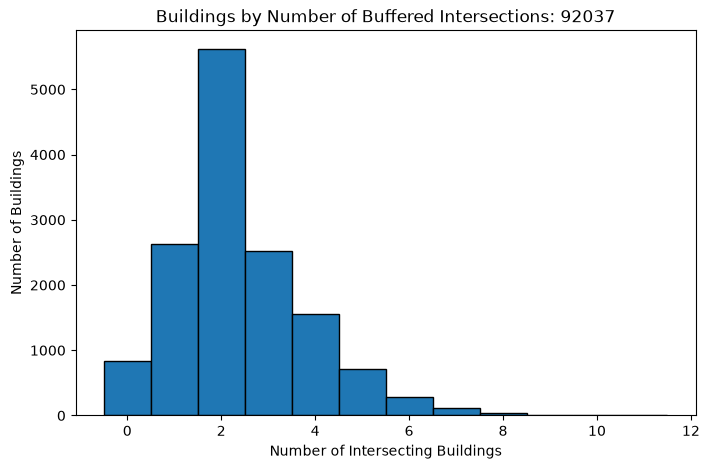

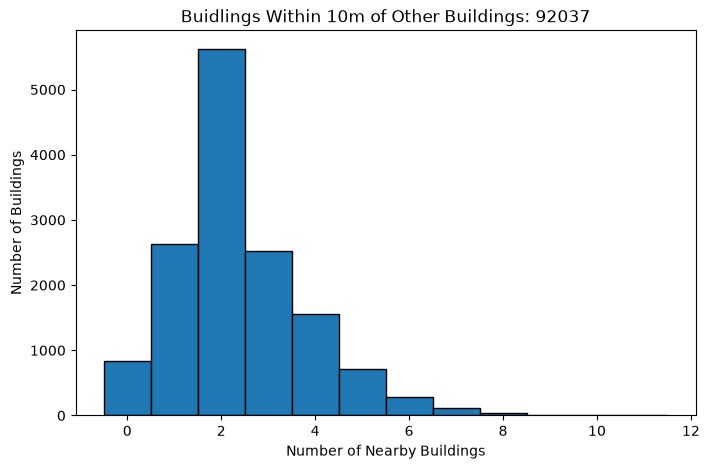

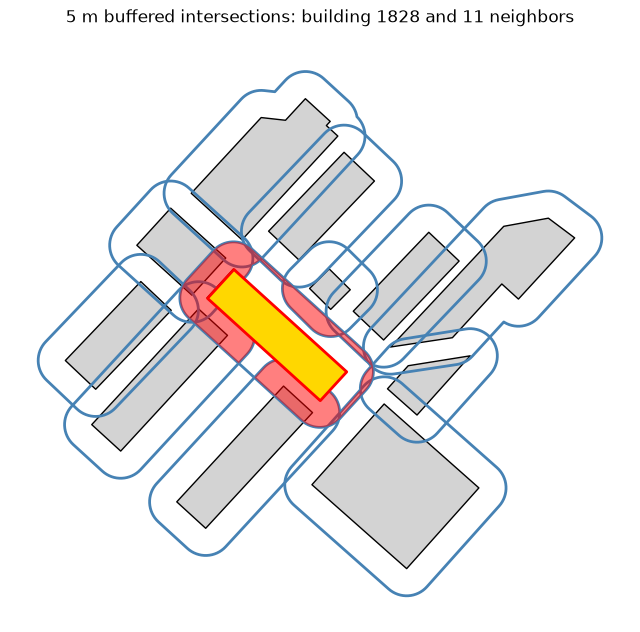

In [10]:
# A 5 m buffer on both buildings means their buffered footprints can
# intersect when the original footprints are at most 10 m apart.
buffer_neighbor_counts = con.execute("""
    WITH source AS (
        SELECT ROW_NUMBER() OVER () - 1 AS building_id, geometry
        FROM read_parquet('../../data/raw/osm_buildings_92037.parquet')
        WHERE geometry IS NOT NULL
    ), buffered AS (
        SELECT building_id, ST_Buffer(geometry, 5) AS geometry
        FROM source
    ), pairs AS (
        SELECT a.building_id, b.building_id AS neighbor_id
        FROM buffered AS a
        JOIN buffered AS b
          ON a.building_id <> b.building_id
         AND ST_Intersects(a.geometry, b.geometry)
    )
    SELECT building_id, COUNT(neighbor_id) AS neighbor_count
    FROM pairs
    GROUP BY building_id
""").df()

# Include buildings with zero intersections in the distribution.
buffer_neighbor_counts = (
    buildings.reset_index(drop=True)
    .assign(building_id=lambda df: df.index)
    .merge(buffer_neighbor_counts, on="building_id", how="left")
    .fillna({"neighbor_count": 0})
)
buffer_neighbor_counts["neighbor_count"] = buffer_neighbor_counts[
    "neighbor_count"
].astype(int)

buffer_distribution = (
    buffer_neighbor_counts["neighbor_count"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_intersections")
    .reset_index(name="number_of_buildings")
)
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.hist(
    buffer_neighbor_counts["neighbor_count"],
    bins=range(
        buffer_neighbor_counts["neighbor_count"].min(),
        buffer_neighbor_counts["neighbor_count"].max() + 2,
    ),
    align="left",
    edgecolor="black",
)
ax1.set_title("Buildings by Number of Buffered Intersections: 92037")
ax1.set_ylabel("Number of Buildings")
ax1.set_xlabel("Number of Intersecting Buildings")

# ST_DWithin with 10 m is the equivalent original-footprint test.
dwithin_neighbor_counts = con.execute("""
    WITH source AS (
        SELECT ROW_NUMBER() OVER () - 1 AS building_id, geometry
        FROM read_parquet('../../data/raw/osm_buildings_92037.parquet')
        WHERE geometry IS NOT NULL
    ), pairs AS (
        SELECT a.building_id, b.building_id AS neighbor_id
        FROM source AS a
        JOIN source AS b
          ON a.building_id <> b.building_id
         AND ST_DWithin(a.geometry, b.geometry, 10)
    )
    SELECT building_id, COUNT(neighbor_id) AS neighbor_count
    FROM pairs
    GROUP BY building_id
""").df()

dwithin_neighbor_counts = (
    buildings.reset_index(drop=True)
    .assign(building_id=lambda df: df.index)
    .merge(dwithin_neighbor_counts, on="building_id", how="left")
    .fillna({"neighbor_count": 0})
)
dwithin_neighbor_counts["neighbor_count"] = dwithin_neighbor_counts[
    "neighbor_count"
].astype(int)

dwithin_distribution = (
    dwithin_neighbor_counts["neighbor_count"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_intersections")
    .reset_index(name="number_of_buildings")
)

fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.hist(
    dwithin_neighbor_counts["neighbor_count"],
    bins=range(
        dwithin_neighbor_counts["neighbor_count"].min(),
        dwithin_neighbor_counts["neighbor_count"].max() + 2,
    ),
    align="left",
    edgecolor="black",
)
ax2.set_title("Buidlings Within 10m of Other Buildings: 92037")
ax2.set_ylabel("Number of Buildings")
ax2.set_xlabel("Number of Nearby Buildings")

# Plot the most connected example and a small local subsection.
target_id = int(buffer_neighbor_counts["neighbor_count"].idxmax())
neighbor_ids = con.execute(f"""
    WITH source AS (
        SELECT ROW_NUMBER() OVER () - 1 AS building_id, geometry
        FROM read_parquet('../../data/raw/osm_buildings_92037.parquet')
        WHERE geometry IS NOT NULL
    ), buffered AS (
        SELECT building_id, ST_Buffer(geometry, 5) AS geometry
        FROM source
    )
    SELECT b.building_id
    FROM buffered AS a
    JOIN buffered AS b
      ON a.building_id <> b.building_id
     AND ST_Intersects(a.geometry, b.geometry)
    WHERE a.building_id = {target_id}
""").df()["building_id"].tolist()

example_ids = [target_id, *neighbor_ids]
example = buildings.iloc[example_ids]
target = buildings.iloc[[target_id]]
buffered_example = example.copy()
buffered_example["geometry"] = buffered_example.geometry.buffer(5)
overlap = buffered_example.iloc[0].geometry.intersection(
    buffered_example.iloc[1:].geometry.union_all()
)
overlap_gdf = gpd.GeoDataFrame(
    {"geometry": [overlap]}, crs=buildings.crs
)

fig, ax = plt.subplots(figsize=(8, 8))
example.plot(ax=ax, color="lightgray", edgecolor="black", linewidth=1)
buffered_example.plot(
    ax=ax, facecolor="none", edgecolor="steelblue", linewidth=2
)
overlap_gdf.plot(ax=ax, color="red", alpha=0.5, edgecolor="none")
target.plot(ax=ax, color="gold", edgecolor="red", linewidth=2)
ax.set_title(
    f"5 m buffered intersections: building {target_id} "
    f"and {len(neighbor_ids)} neighbors"
)
ax.set_axis_off()
plt.show()
